In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [3]:
df = pd.read_csv("spam.csv", encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
df = df[["v1", "v2"]]

df.columns = ["label", "message"]

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
print("Dataset shape:", df.shape)

print("\nLabel distribution:")
print(df["label"].value_counts())

Dataset shape: (5572, 2)

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


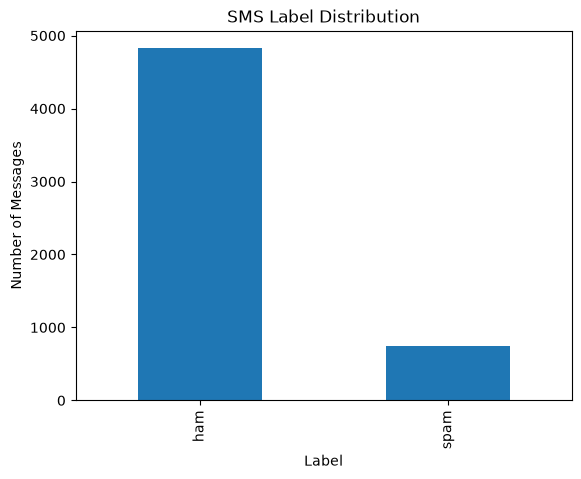

In [6]:
df["label"].value_counts().plot(kind="bar")

plt.title("SMS Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Messages")

plt.show()

In [7]:
def clean_text(text):

    # Küçük harfe çevir
    text = text.lower()

    # Fazla boşlukları temizle
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [9]:
cleaned_messages = [
    clean_text(message)
    for message in df["message"]
]

In [10]:
cleaned_df = pd.DataFrame({
    "original": df["message"],
    "cleaned": cleaned_messages,
    "label": df["label"]
})

cleaned_df.head(10)

,original,cleaned,label
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",ham
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,spam
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro...",ham
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it's been 3 week's n...,spam
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me. ...,ham
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request 'melle melle (oru minnamin...,ham
8,WINNER!! As a valued network customer you have...,winner!! as a valued network customer you have...,spam
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more? u r entitle...,spam


In [12]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    cleaned_messages,
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)


In [13]:
vectorizer = TfidfVectorizer(
    min_df=2,
    max_features=5000
)

X_train = vectorizer.fit_transform(X_train_text)

X_test = vectorizer.transform(X_test_text)

In [14]:
feature_names = vectorizer.get_feature_names_out()

print("Number of features:", len(feature_names))

print("\nFirst 20 features:")
print(feature_names[:20])

print("\nMatrix shape:")
print(X_train.shape)

Number of features: 3641

First 20 features:
['00' '000' '01223585334' '02' '0207' '02073162414' '03' '04' '05'
 '050703' '0578' '06' '07' '07123456789' '07742676969' '07781482378'
 '07821230901' '07xxxxxxxxx' '0800' '08000839402']

Matrix shape:
(4457, 3641)


In [15]:
small_tfidf = X_train[:5, :20].toarray()

tfidf_df = pd.DataFrame(
    small_tfidf,
    columns=feature_names[:20]
)

tfidf_df

,00,000,01223585334,02,0207,02073162414,03,04,05,050703,0578,06,07,07123456789,07742676969,07781482378,07821230901,07xxxxxxxxx,0800,08000839402
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
sample_index = 0

sample_vector = X_train[sample_index]

non_zero_indices = sample_vector.nonzero()[1]

sample_words = feature_names[non_zero_indices]

sample_scores = sample_vector.toarray()[0][non_zero_indices]

sample_tfidf = pd.DataFrame({
    "word": sample_words,
    "tfidf": sample_scores
})

sample_tfidf = sample_tfidf.sort_values(
    "tfidf",
    ascending=False
)

sample_tfidf.head(15)

,word,tfidf
4,bye,0.623084
2,nothing,0.486037
3,great,0.403217
0,going,0.365792
1,on,0.281329


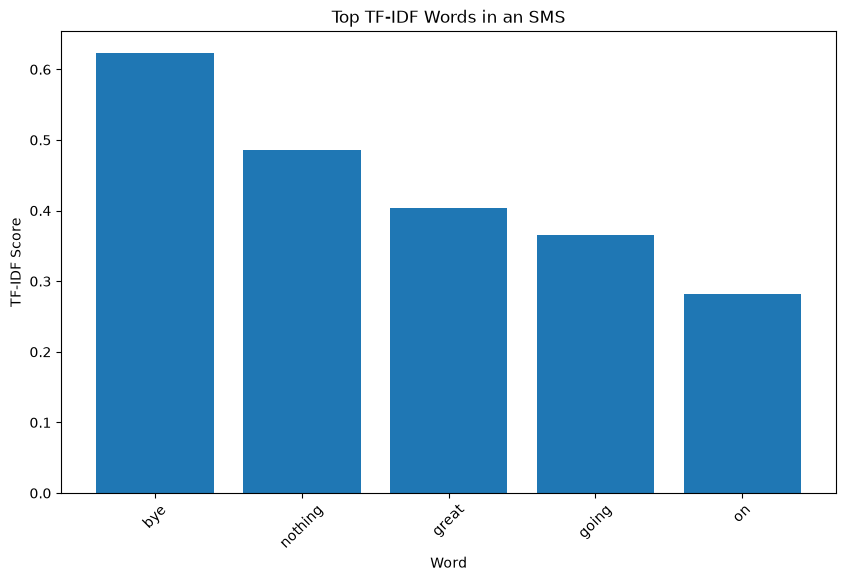

In [17]:
top_words = sample_tfidf.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top_words["word"],
    top_words["tfidf"]
)

plt.title("Top TF-IDF Words in an SMS")
plt.xlabel("Word")
plt.ylabel("TF-IDF Score")

plt.xticks(rotation=45)

plt.show()

In [19]:
model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       966
        spam       0.99      0.83      0.90       149

    accuracy                           0.98      1115
   macro avg       0.98      0.91      0.94      1115
weighted avg       0.98      0.98      0.97      1115



In [20]:
my_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting at 7 tonight?"
]

my_messages_cleaned = [
    clean_text(message)
    for message in my_messages
]

my_messages_tfidf = vectorizer.transform(
    my_messages_cleaned
)

predictions = model.predict(my_messages_tfidf)

for message, prediction in zip(my_messages, predictions):

    print("Message:", message)
    print("Prediction:", prediction)
    print("-" * 60)

Message: Congratulations! You have won a free prize. Call now!
Prediction: spam
------------------------------------------------------------
Message: Hey, are we meeting at 7 tonight?
Prediction: ham
------------------------------------------------------------
